# Assignment 3: Time-Series Data: Forecasting Jena Air Temperature with RNNs

**Research question:** Which of the methods from class (changing the number of units in a stacked RNN, using LSTM instead of GRU, or adding 1D convolutions before an RNN) gives the lowest validation MAE when forecasting air temperature 24 hours ahead? And does the best model also beat the common-sense baseline on the test set?

**Data:** Jena Climate dataset, 2009–2016, recorded by the Max Planck Institute for Biogeochemistry: 14 weather variables measured every 10 minutes. Source: https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip

**How to run (Kaggle):** Settings → Accelerator → GPU T4 x2, Internet on. Then Save Version → Save & Run All.

**How to run (general):**
1. Use a T4 GPU. **Colab:** Runtime → Change runtime type → T4 GPU. **Kaggle:** Settings → Accelerator → GPU T4, and turn Internet on (needed to download the data).
2. Run the cells from top to bottom.
3. Results are saved in `assignment3/` in the working folder (`/content` on Colab, `/kaggle/working` on Kaggle), and each section ends with a backup zip, `assignment3_backup.zip`. Finished experiments are skipped when a cell is re-run. To continue in a new session, upload the latest backup zip first (Colab: to `/content`; Kaggle: Add Input → Upload): it is restored automatically.

**Contents:** 1–3 Setup, data and preparation · 4 Common-sense baseline · 5 Training setup · 6 Course reference models · 7 Method 1: units in the stacked setup · 8 Method 2: LSTM instead of GRU · 9 Method 3: Conv1D + RNN · 10 Test-set evaluation · 11 Results · 12 Reproducibility and limitations

## 1–3. Setup, data and preparation
The data pipeline, the models and the training routine live in one file, `a3_lib.py`, written to the working folder by the next cell. The notebook imports it for the checks, tables and plots. Each model is trained by running that file in its own Python process, because TensorFlow does not return all the memory of a trained model while the notebook stays open.

- **Quality checks:** 327 repeated timestamps (exact copies) are removed, and 38 wind-speed error codes (−9999) are replaced with 0, as in the TensorFlow time series tutorial. Five gaps in the record are listed and kept, as in class.
- **Split:** chronological, 50% train (2009–2012), 25% validation (2013–2014), 25% test (2015–2016).
- **Normalization:** each variable is standardized with the training rows' mean and standard deviation only.
- **Windows:** 120 hourly steps (5 days, one reading per hour) and a target 24 hours after the last step. These are the same samples as `keras.utils.timeseries_dataset_from_array` in class (checked window by window), but each batch is cut with one vectorized gather, which keeps RAM low and makes each epoch faster.

In [1]:
%%writefile a3_lib.py
"""Assignment 3 library: data pipeline, models and training for one experiment.
The notebook imports it for data checks, tables and plots; each model is trained by running
`python a3_lib.py <exp_id>` in its own process, so all its RAM is returned when it finishes."""
import os, sys, gc, json, time, zipfile, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers
warnings.filterwarnings("ignore", category=UserWarning)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)   # notebook and training process share the GPU

# ---------- Settings ----------
SEED = 42
SAMPLING_RATE = 6          # data every 10 minutes -> keep 1 reading per hour
SEQUENCE_LENGTH = 120      # 120 hourly steps = 5 days of history per sample
HORIZON_HOURS = 24         # target: temperature 24 hours after the last step
BATCH_SIZE = 256
DELAY = SAMPLING_RATE * (SEQUENCE_LENGTH + HORIZON_HOURS - 1)   # 858 raw steps from window start to target
MAX_EPOCHS = int(os.environ.get("A3_MAX_EPOCHS", 30))
PATIENCE = 3
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "/content"   # Kaggle or Colab
BASE_DIR = os.environ.get("A3_BASE_DIR", f"{WORK_DIR}/assignment3")
DATA_DIR, RESULTS_DIR, CKPT_DIR, FIG_DIR = (f"{BASE_DIR}/{d}" for d in ["data", "results", "checkpoints", "figures"])
for folder in [DATA_DIR, RESULTS_DIR, CKPT_DIR, FIG_DIR]:
    os.makedirs(folder, exist_ok=True)
keras.utils.set_random_seed(SEED)

# ---------- Load (read straight from the zip) ----------
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
zip_path = keras.utils.get_file("jena_climate_2009_2016.csv.zip", URL, cache_dir=DATA_DIR, cache_subdir="")
with zipfile.ZipFile(zip_path) as archive:
    member = next(n for n in archive.namelist() if n.endswith(".csv") and not n.startswith("__MACOSX"))
    df = pd.read_csv(archive.open(member))
RAW_SHAPE, RAW_RANGE = df.shape, (df["Date Time"].iloc[0], df["Date Time"].iloc[-1])

# ---------- Quality checks and cleaning ----------
time_index = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
repeated = time_index.duplicated()
N_REPEATED, N_EXACT_COPIES = int(repeated.sum()), int(df.duplicated().sum())
df, time_index = df[~repeated].reset_index(drop=True), time_index[~repeated].reset_index(drop=True)
steps = time_index.diff()
is_gap = steps > pd.Timedelta(minutes=10)
gaps = pd.DataFrame({"gap starts after": time_index.shift(1)[is_gap], "length": steps[is_gap]})
WIND_FIXES = {}
for col in ["wv (m/s)", "max. wv (m/s)"]:
    bad = df[col] == -9999.0
    WIND_FIXES[col] = int(bad.sum())
    df.loc[bad, col] = 0.0
FEATURES = [c for c in df.columns if c != "Date Time"]
TEMP_COL = FEATURES.index("T (degC)")
raw = df[FEATURES].to_numpy(np.float32)
temperature = df["T (degC)"].to_numpy(np.float32)

# ---------- Chronological split (50/25/25) and normalization with training rows only ----------
num_train, num_val = int(0.5 * len(raw)), int(0.25 * len(raw))
num_test = len(raw) - num_train - num_val
split_table = pd.DataFrame({"split": ["train", "validation", "test"], "rows": [num_train, num_val, num_test],
                            "from": time_index.iloc[[0, num_train, num_train + num_val]].values,
                            "to": time_index.iloc[[num_train - 1, num_train + num_val - 1, len(raw) - 1]].values})
mean, std = raw[:num_train].mean(axis=0), raw[:num_train].std(axis=0)
data_norm = (raw - mean) / std
N_FEATURES = data_norm.shape[1]
del df, raw
gc.collect()

# ---------- Windows ----------
# Same samples as keras.utils.timeseries_dataset_from_array in class (120 hourly steps from row i;
# target = temperature at row i + DELAY), but each batch is cut with one vectorized gather.
with tf.device("/CPU:0"):
    data_tf, temp_tf = tf.constant(data_norm), tf.constant(temperature)
    offsets = tf.range(SEQUENCE_LENGTH, dtype=tf.int64) * SAMPLING_RATE

def make_windows(first_row, last_row, shuffle=False):
    """Every window whose inputs lie in rows [first_row, last_row)."""
    starts = np.arange(first_row, last_row - (SEQUENCE_LENGTH - 1) * SAMPLING_RATE)
    ds = tf.data.Dataset.from_tensor_slices(starts)
    if shuffle:
        ds = ds.shuffle(len(starts), seed=SEED, reshuffle_each_iteration=True)
    def gather(batch_starts):
        return tf.gather(data_tf, batch_starts[:, None] + offsets), tf.gather(temp_tf, batch_starts + DELAY)
    return ds.batch(BATCH_SIZE).map(gather, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

train_ds = make_windows(0, num_train, shuffle=True)
val_ds = make_windows(num_train, num_train + num_val)
test_ds = make_windows(num_train + num_val, len(data_norm) - DELAY)

def describe_data():
    """Printed checks for the notebook."""
    x, y = next(iter(train_ds))
    gpus = tf.config.list_physical_devices("GPU")
    print("Saving to:", BASE_DIR, "| TensorFlow", tf.__version__, "| Keras", keras.__version__,
          "| GPU:", tf.config.experimental.get_device_details(gpus[0]).get("device_name") if gpus else "NONE")
    print(f"Raw file: {RAW_SHAPE[0]:,} rows x {RAW_SHAPE[1]} columns, {RAW_RANGE[0]} to {RAW_RANGE[1]}")
    print(f"Repeated timestamps removed: {N_REPEATED} (exact copies of an earlier row: {N_EXACT_COPIES})")
    for col, n in WIND_FIXES.items():
        print(f"{col}: {n} error values (-9999) replaced with 0")
    print(f"Clean data: {len(data_norm):,} rows x {N_FEATURES} inputs | in time order: {time_index.is_monotonic_increasing} | gaps > 10 min: {len(gaps)}")
    print("Batch:", tuple(x.shape), tuple(y.shape), "| batches (train/val/test):",
          [int(d.cardinality()) for d in (train_ds, val_ds, test_ds)],
          f"| train mean {data_norm[:num_train].mean():.3f}, std {data_norm[:num_train].std():.3f}")

def evaluate_naive_method(dataset):
    """MAE (°C) of 'temperature in 24 h = temperature now' (last reading of each window)."""
    errors = [np.abs(x[:, -1, TEMP_COL].numpy() * std[TEMP_COL] + mean[TEMP_COL] - y.numpy()) for x, y in dataset]
    return float(np.concatenate(errors).mean())

# ---------- Model builders ----------
def rnn_layer(kind, units, recurrent_dropout=0.0, return_sequences=False):
    """GRU or LSTM. With recurrent dropout the loop is unrolled: same maths, ~10x faster on a T4."""
    layer_class = layers.GRU if kind == "GRU" else layers.LSTM
    return layer_class(units, recurrent_dropout=recurrent_dropout,
                       return_sequences=return_sequences, unroll=recurrent_dropout > 0)

def dense_model():
    inputs = keras.Input(shape=(SEQUENCE_LENGTH, N_FEATURES))
    x = layers.Dense(16, activation="relu")(layers.Flatten()(inputs))
    return keras.Model(inputs, layers.Dense(1)(x))

def single_rnn(kind, units, recurrent_dropout=0.0, dropout_after=0.0):
    def build():
        inputs = keras.Input(shape=(SEQUENCE_LENGTH, N_FEATURES))
        x = rnn_layer(kind, units, recurrent_dropout)(inputs)
        x = layers.Dropout(dropout_after)(x) if dropout_after else x
        return keras.Model(inputs, layers.Dense(1)(x))
    return build

def stacked_rnn(kind, units_1, units_2, recurrent_dropout=0.5, dropout_after=0.5):
    def build():
        inputs = keras.Input(shape=(SEQUENCE_LENGTH, N_FEATURES))
        x = rnn_layer(kind, units_1, recurrent_dropout, return_sequences=True)(inputs)
        x = rnn_layer(kind, units_2, recurrent_dropout)(x)
        return keras.Model(inputs, layers.Dense(1)(layers.Dropout(dropout_after)(x)))
    return build

def conv_rnn(kind, units=32, filters=32, kernel=6, pool=2, recurrent_dropout=0.5, dropout_after=0.5):
    """Conv1D layers extract 6-hour patterns; pooling halves the sequence before the RNN reads it in order."""
    def build():
        inputs = keras.Input(shape=(SEQUENCE_LENGTH, N_FEATURES))
        x = layers.Conv1D(filters, kernel, activation="relu", padding="same")(inputs)
        x = layers.MaxPooling1D(pool)(x)
        x = layers.Conv1D(filters, kernel, activation="relu", padding="same")(x)
        x = rnn_layer(kind, units, recurrent_dropout)(x)
        return keras.Model(inputs, layers.Dense(1)(layers.Dropout(dropout_after)(x)))
    return build

# exp_id -> (name, method, builder)
EXPERIMENTS = {
    "exp01_dense": ("Dense (Flatten, Dense 16)", "Course reference", dense_model),
    "exp02_lstm16": ("LSTM(16)", "Course reference", single_rnn("LSTM", 16)),
    "exp03_lstm32_rd": ("LSTM(32) + recurrent dropout", "Course reference", single_rnn("LSTM", 32, recurrent_dropout=0.25, dropout_after=0.5)),
    "exp04_gru32x2": ("Stacked GRU 32/32", "Course reference", stacked_rnn("GRU", 32, 32)),
    "exp05_gru16x2": ("Stacked GRU 16/16", "Method 1: units", stacked_rnn("GRU", 16, 16)),
    "exp06_gru64x2": ("Stacked GRU 64/64", "Method 1: units", stacked_rnn("GRU", 64, 64)),
    "exp07_gru64x32": ("Stacked GRU 64/32", "Method 1: units", stacked_rnn("GRU", 64, 32)),
    "exp08_lstm32x2": ("Stacked LSTM 32/32", "Method 2: LSTM vs GRU", stacked_rnn("LSTM", 32, 32)),
    "exp09_lstm16x16": ("Stacked LSTM 16/16", "Method 2: LSTM vs GRU", stacked_rnn("LSTM", 16, 16)),
    "exp09_lstm64x64": ("Stacked LSTM 64/64", "Method 2: LSTM vs GRU", stacked_rnn("LSTM", 64, 64)),
    "exp09_lstm64x32": ("Stacked LSTM 64/32", "Method 2: LSTM vs GRU", stacked_rnn("LSTM", 64, 32)),
    "exp10_conv_gru": ("Conv1D + GRU 32", "Method 3: Conv1D + RNN", conv_rnn("GRU")),
    "exp11_conv_lstm": ("Conv1D + LSTM 32", "Method 3: Conv1D + RNN", conv_rnn("LSTM")),
}

# ---------- Training (one experiment per process) ----------
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.start = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.start)

def run_experiment(exp_id):
    """Train one model, keep the epoch with the lowest validation MAE, save result, history and model."""
    name, method, build_fn = EXPERIMENTS[exp_id]
    model = build_fn()
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-3), loss="mse", metrics=["mae"])
    timer, start = EpochTimer(), time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, verbose=2, callbacks=[
        keras.callbacks.ModelCheckpoint(f"{CKPT_DIR}/{exp_id}.keras", monitor="val_mae", save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_mae", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=2),
        timer]).history
    best = int(np.argmin(h["val_mae"]))
    result = {"exp_id": exp_id, "name": name, "method": method, "params": int(model.count_params()),
              "epochs_run": len(h["loss"]), "best_epoch": best + 1, "best_val_mae": float(h["val_mae"][best]),
              "train_mae_at_best": float(h["mae"][best]), "minutes": round((time.time() - start) / 60, 1),
              "seconds_per_epoch": round(float(np.mean(timer.times)), 1), "seed": SEED}
    with open(f"{RESULTS_DIR}/{exp_id}.json", "w") as f:
        json.dump(result, f, indent=2)
    pd.DataFrame(h).to_csv(f"{RESULTS_DIR}/{exp_id}_history.csv", index=False)
    print(f"{exp_id} | {name}: best validation MAE {result['best_val_mae']:.3f} °C at epoch {result['best_epoch']} "
          f"of {result['epochs_run']} | {result['params']:,} parameters | {result['minutes']} min")

def test_experiment(exp_id):
    """Evaluate a saved best model once on the test set and add the test MAE to its result file."""
    model = keras.models.load_model(f"{CKPT_DIR}/{exp_id}.keras")
    test_mae = float(model.evaluate(test_ds, verbose=0)[1])
    path = f"{RESULTS_DIR}/{exp_id}.json"
    with open(path) as f:
        result = json.load(f)
    result["test_mae"] = test_mae
    with open(path, "w") as f:
        json.dump(result, f, indent=2)
    print(f"{exp_id} | {result['name']}: test MAE {test_mae:.3f} °C (validation {result['best_val_mae']:.3f} °C)")

if __name__ == "__main__":
    keras.utils.set_random_seed(SEED)
    if sys.argv[1] == "test":
        test_experiment(sys.argv[2])
    else:
        run_experiment(sys.argv[1])


Writing a3_lib.py


In [2]:
import os, sys, json, glob, shutil, zipfile, subprocess, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
LIB_DIR = os.getcwd()          # a3_lib.py is written here (/content on Colab, /kaggle/working on Kaggle)
sys.path.insert(0, LIB_DIR)
import a3_lib as lib
importlib.reload(lib)            # picks up any edit to the library cell
BASE_DIR, RESULTS_DIR, CKPT_DIR, FIG_DIR = lib.BASE_DIR, lib.RESULTS_DIR, lib.CKPT_DIR, lib.FIG_DIR

# Restore earlier results from an uploaded backup (Colab: /content; Kaggle: added as input data)
BACKUP_ZIP = os.path.join(os.path.dirname(BASE_DIR), "assignment3_backup.zip")
if not glob.glob(f"{RESULTS_DIR}/exp*.json"):
    zips = [BACKUP_ZIP] if os.path.exists(BACKUP_ZIP) else glob.glob("/kaggle/input/**/assignment3_backup.zip", recursive=True)
    unpacked = glob.glob("/kaggle/input/**/results/exp*.json", recursive=True)
    if zips:
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(BASE_DIR)
    elif unpacked:                    # Kaggle may unzip an uploaded zip automatically
        source = os.path.dirname(os.path.dirname(unpacked[0]))
        for folder in ["results", "checkpoints", "figures"]:
            if os.path.isdir(f"{source}/{folder}"):
                shutil.copytree(f"{source}/{folder}", f"{BASE_DIR}/{folder}", dirs_exist_ok=True)
    if zips or unpacked:
        print("Restored from backup:", sorted(os.path.basename(p)[:-5] for p in glob.glob(f"{RESULTS_DIR}/exp*.json")))

lib.describe_data()
display(lib.split_table)
display(lib.gaps)

13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Saving to: /kaggle/working/assignment3 | TensorFlow 2.21.0 | Keras 3.13.2 | GPU: Tesla T4
Raw file: 420,551 rows x 15 columns, 01.01.2009 00:10:00 to 01.01.2017 00:00:00
Repeated timestamps removed: 327 (exact copies of an earlier row: 327)
wv (m/s): 18 error values (-9999) replaced with 0
max. wv (m/s): 20 error values (-9999) replaced with 0
Clean data: 420,224 rows x 14 inputs | in time order: True | gaps > 10 min: 5
Batch: (256, 120, 14) (256,) | batches (train/val/test): [818, 408, 405] | train mean 0.000, std 1.000


,split,rows,from,to
0,train,210112,2009-01-01 00:10:00,2012-12-30 03:00:00
1,validation,105056,2012-12-30 03:10:00,2014-12-30 08:30:00
2,test,105056,2014-12-30 08:40:00,2017-01-01 00:00:00


,gap starts after,length
40378,2009-10-08 09:40:00,0 days 00:30:00
229875,2013-05-16 08:50:00,0 days 00:20:00
293229,2014-07-30 08:00:00,0 days 00:20:00
301346,2014-09-24 17:00:00,0 days 16:00:00
410940,2016-10-25 10:30:00,3 days 02:20:00


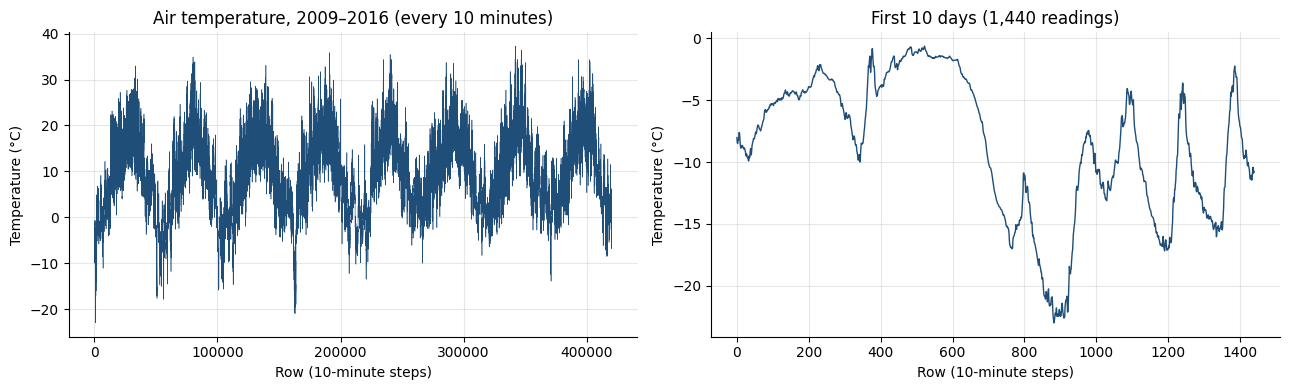

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(lib.temperature, color="#1F4E79", linewidth=0.4)
axes[0].set_title("Air temperature, 2009–2016 (every 10 minutes)")
axes[1].plot(lib.temperature[:1440], color="#1F4E79", linewidth=1)
axes[1].set_title("First 10 days (1,440 readings)")
for ax in axes:
    ax.set_xlabel("Row (10-minute steps)"); ax.set_ylabel("Temperature (°C)")
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_temperature_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Common-sense baseline
A forecast with no learning: the temperature 24 hours from now equals the temperature now. Any model has to beat it to be worth using. Course result: validation MAE 2.44 °C, test MAE 2.62 °C.

In [4]:
baseline_val_mae = lib.evaluate_naive_method(lib.val_ds)
baseline_test_mae = lib.evaluate_naive_method(lib.test_ds)
print(f"Common-sense baseline -> validation MAE {baseline_val_mae:.3f} °C | test MAE {baseline_test_mae:.3f} °C (course: 2.44 / 2.62)")
with open(f"{RESULTS_DIR}/exp00_baseline.json", "w") as f:
    json.dump({"exp_id": "exp00_baseline", "name": "Common-sense baseline", "method": "Baseline",
               "params": 0, "best_val_mae": baseline_val_mae, "test_mae": baseline_test_mae}, f, indent=2)

Common-sense baseline -> validation MAE 2.444 °C | test MAE 2.622 °C (course: 2.44 / 2.62)


## 5. Training setup
Every model is trained the same way, so only the architecture changes between experiments:
- **Loss and metric:** MSE loss (smooth near zero, which suits gradient descent) and MAE in °C as the metric, as in class. **Optimizer:** RMSprop, learning rate 1e-3.
- **Callbacks:** keep the epoch with the lowest validation MAE; stop after 3 epochs without improvement (up to 30 epochs); halve the learning rate after 2 epochs without improvement.
- **Selection:** models are compared on validation MAE only. The test set is used once, at the end.
- **One process per model:** memory used by TensorFlow grew by 0.6–2 GB with every model trained in the same session, so each model runs in its own process and all its memory is freed when it finishes.
- **Recurrent dropout and speed:** recurrent dropout turns off the fast cuDNN GPU path. Measured on a Colab T4 (GRU with 32 units, one training epoch):

| Version | Seconds per epoch |
|---|---|
| cuDNN, no recurrent dropout | 29 |
| Recurrent dropout, standard loop | 310 |
| Recurrent dropout, XLA compilation | 299 |
| Recurrent dropout, unrolled loop (`unroll=True`) | 30 |

Unrolling changes only how the loop over the 120 fixed steps runs, not the model's equations, so every layer with recurrent dropout is unrolled.

In [5]:
NOISE = ("E0000 ", "W0000 ", "I0000 ", "WARNING: All log messages", "oneDNN", "TF-TRT", "cuda_", "absl::")

def _run_in_own_process(args):
    """Run a3_lib.py in a separate Python process and stream its output; its RAM is freed when it exits."""
    env = dict(os.environ, TF_CPP_MIN_LOG_LEVEL="2", A3_BASE_DIR=BASE_DIR)
    proc = subprocess.Popen([sys.executable, lib.__file__, *args], stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, env=env)
    for line in proc.stdout:
        if not any(s in line for s in NOISE):
            print(line, end="", flush=True)
    if proc.wait() != 0:
        print(f"*** {' '.join(args)} stopped with exit code {proc.returncode}: see the messages above")

def train(exp_ids):
    """Train each experiment in its own process; finished experiments are skipped."""
    for exp_id in exp_ids:
        path = f"{RESULTS_DIR}/{exp_id}.json"
        if os.path.exists(path):
            with open(path) as f:
                print(f"{exp_id} already finished: best validation MAE {json.load(f)['best_val_mae']:.3f} °C")
            continue
        _run_in_own_process([exp_id])

def evaluate_on_test(exp_ids):
    for exp_id in exp_ids:
        _run_in_own_process(["test", exp_id])

def results_table():
    rows = []
    for path in sorted(glob.glob(f"{RESULTS_DIR}/exp*.json")):
        with open(path) as f:
            rows.append(json.load(f))
    table = pd.DataFrame(rows)
    table["val gain vs baseline (%)"] = (1 - table["best_val_mae"] / baseline_val_mae) * 100
    cols = ["exp_id", "name", "method", "params", "best_val_mae", "val gain vs baseline (%)", "test_mae",
            "train_mae_at_best", "best_epoch", "epochs_run", "seconds_per_epoch", "minutes"]
    return table[[c for c in cols if c in table.columns]].round(3)

def plot_curves(exp_ids, title, filename):
    """Training vs validation MAE per epoch, with the baseline as a reference line."""
    fig, axes = plt.subplots(1, len(exp_ids), figsize=(4.3 * len(exp_ids), 3.5), sharey=True, squeeze=False)
    for ax, exp_id in zip(axes[0], exp_ids):
        h = pd.read_csv(f"{RESULTS_DIR}/{exp_id}_history.csv")
        with open(f"{RESULTS_DIR}/{exp_id}.json") as f:
            ax.set_title(json.load(f)["name"], fontsize=10)
        epochs = range(1, len(h) + 1)
        ax.plot(epochs, h["mae"], color="#8FA9C4", linewidth=1.5, label="Training MAE")
        ax.plot(epochs, h["val_mae"], color="#1F4E79", linewidth=2, label="Validation MAE")
        ax.axhline(baseline_val_mae, color="#C8102E", linestyle="--", linewidth=1, label="Baseline (validation)")
        ax.set_xlabel("Epoch"); ax.set_ylim(1.8, 3.6); ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0][0].set_ylabel("MAE (°C)"); axes[0][0].legend(fontsize=8)
    fig.suptitle(title, fontsize=12); plt.tight_layout()
    fig.savefig(f"{FIG_DIR}/{filename}", dpi=150, bbox_inches="tight"); plt.show()

def backup_results():
    """Zip results, figures and saved models (the working disk is wiped when the session ends)."""
    with zipfile.ZipFile(BACKUP_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in [RESULTS_DIR, FIG_DIR, CKPT_DIR]:
            for path in glob.glob(f"{folder}/*"):
                z.write(path, os.path.relpath(path, BASE_DIR))
    try:
        from google.colab import files
        files.download(BACKUP_ZIP)
    except Exception:
        print("Saved", BACKUP_ZIP, "- download it from the Files panel (Colab) or the Output panel (Kaggle).")

print("Helpers ready. Each model trains in its own process, so RAM is returned after every run.")

Helpers ready. Each model trains in its own process, so RAM is returned after every run.


## 6. Course reference models
The four models from class are re-run with the same pipeline, so the improvements in Sections 7–9 are compared against numbers produced here, not copied from the slides.

Epoch 1/30
818/818 - 6s - 8ms/step - loss: 12.3359 - mae: 2.7124 - val_loss: 10.4688 - val_mae: 2.5514 - learning_rate: 0.0010
Epoch 2/30
818/818 - 3s - 4ms/step - loss: 8.8127 - mae: 2.3311 - val_loss: 9.9227 - val_mae: 2.4813 - learning_rate: 0.0010
Epoch 3/30
818/818 - 3s - 4ms/step - loss: 8.1222 - mae: 2.2408 - val_loss: 12.4869 - val_mae: 2.8016 - learning_rate: 0.0010
Epoch 4/30
818/818 - 3s - 4ms/step - loss: 7.7359 - mae: 2.1866 - val_loss: 10.4130 - val_mae: 2.5450 - learning_rate: 0.0010
Epoch 5/30
818/818 - 3s - 4ms/step - loss: 6.9075 - mae: 2.0639 - val_loss: 10.7625 - val_mae: 2.5930 - learning_rate: 5.0000e-04
exp01_dense | Dense (Flatten, Dense 16): best validation MAE 2.481 °C at epoch 2 of 5 | 26,913 parameters | 0.3 min
Epoch 1/30
818/818 - 9s - 11ms/step - loss: 43.7232 - mae: 4.8187 - val_loss: 13.0756 - val_mae: 2.7340 - learning_rate: 0.0010
Epoch 2/30
818/818 - 8s - 9ms/step - loss: 11.1105 - mae: 2.5950 - val_loss: 9.8578 - val_mae: 2.4455 - learning_rate: 0.0

,exp_id,name,method,params,best_val_mae,val gain vs baseline (%),test_mae,train_mae_at_best,best_epoch,epochs_run,seconds_per_epoch,minutes
0,exp00_baseline,Common-sense baseline,Baseline,0,2.444,0.000,2.622,NaN,NaN,NaN,NaN,NaN
1,exp01_dense,"Dense (Flatten, Dense 16)",Course reference,26913,2.481,-1.511,NaN,2.331,2.0,5.0,3.9,0.3
2,exp02_lstm16,LSTM(16),Course reference,2001,2.415,1.220,NaN,2.356,7.0,10.0,7.8,1.3
3,exp03_lstm32_rd,LSTM(32) + recurrent dropout,Course reference,6049,2.291,6.277,NaN,2.782,7.0,10.0,28.9,4.8
4,exp04_gru32x2,Stacked GRU 32/32,Course reference,10977,2.253,7.848,NaN,2.662,9.0,12.0,56.4,11.3


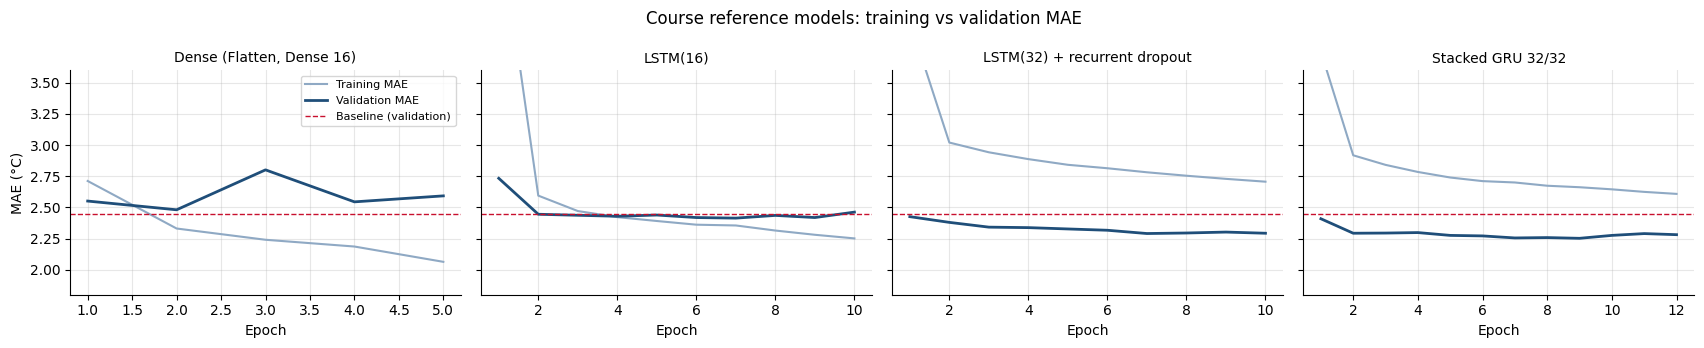

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
course_ids = ["exp01_dense", "exp02_lstm16", "exp03_lstm32_rd", "exp04_gru32x2"]
train(course_ids)
display(results_table())
plot_curves(course_ids, "Course reference models: training vs validation MAE", "fig_curves_course_models.png")
backup_results()

## 7. Method 1: Adjusting the number of units in the stacked setup
The stacked GRU from class (32/32 units, exp04) is the reference. Three variants change only the number of units: smaller (16/16), larger (64/64), and a funnel with a wider first layer than the second (64/32). Recurrent dropout (0.5), dropout before the output (0.5), the optimizer and the callbacks stay the same.

Epoch 1/30
818/818 - 397s - 486ms/step - loss: 42.7589 - mae: 4.8284 - val_loss: 12.6583 - val_mae: 2.6697 - learning_rate: 0.0010
Epoch 2/30
818/818 - 24s - 30ms/step - loss: 18.5396 - mae: 3.2882 - val_loss: 9.6584 - val_mae: 2.3905 - learning_rate: 0.0010
Epoch 3/30
818/818 - 24s - 29ms/step - loss: 17.0299 - mae: 3.1631 - val_loss: 9.1728 - val_mae: 2.3453 - learning_rate: 0.0010
Epoch 4/30
818/818 - 24s - 29ms/step - loss: 16.1936 - mae: 3.0855 - val_loss: 8.8770 - val_mae: 2.3063 - learning_rate: 0.0010
Epoch 5/30
818/818 - 24s - 29ms/step - loss: 15.6238 - mae: 3.0330 - val_loss: 8.8485 - val_mae: 2.2993 - learning_rate: 0.0010
Epoch 6/30
818/818 - 24s - 29ms/step - loss: 15.0334 - mae: 2.9777 - val_loss: 8.8627 - val_mae: 2.3149 - learning_rate: 0.0010
Epoch 7/30
818/818 - 24s - 29ms/step - loss: 14.6302 - mae: 2.9395 - val_loss: 8.5649 - val_mae: 2.2693 - learning_rate: 0.0010
Epoch 8/30
818/818 - 24s - 29ms/step - loss: 14.3214 - mae: 2.9126 - val_loss: 8.4362 - val_mae: 2.25

,exp_id,name,method,params,best_val_mae,val gain vs baseline (%),test_mae,train_mae_at_best,best_epoch,epochs_run,seconds_per_epoch,minutes
0,exp00_baseline,Common-sense baseline,Baseline,0,2.444,0.000,2.622,NaN,NaN,NaN,NaN,NaN
1,exp01_dense,"Dense (Flatten, Dense 16)",Course reference,26913,2.481,-1.511,NaN,2.331,2.0,5.0,3.9,0.3
2,exp02_lstm16,LSTM(16),Course reference,2001,2.415,1.220,NaN,2.356,7.0,10.0,7.8,1.3
3,exp03_lstm32_rd,LSTM(32) + recurrent dropout,Course reference,6049,2.291,6.277,NaN,2.782,7.0,10.0,28.9,4.8
4,exp04_gru32x2,Stacked GRU 32/32,Course reference,10977,2.253,7.848,NaN,2.662,9.0,12.0,56.4,11.3
5,exp05_gru16x2,Stacked GRU 16/16,Method 1: units,3185,2.255,7.734,NaN,2.913,8.0,11.0,57.9,10.6
6,exp06_gru64x2,Stacked GRU 64/64,Method 1: units,40385,2.250,7.947,NaN,2.359,9.0,12.0,60.5,12.1
7,exp07_gru64x32,Stacked GRU 64/32,Method 1: units,24801,2.226,8.934,NaN,2.591,9.0,12.0,58.8,11.8


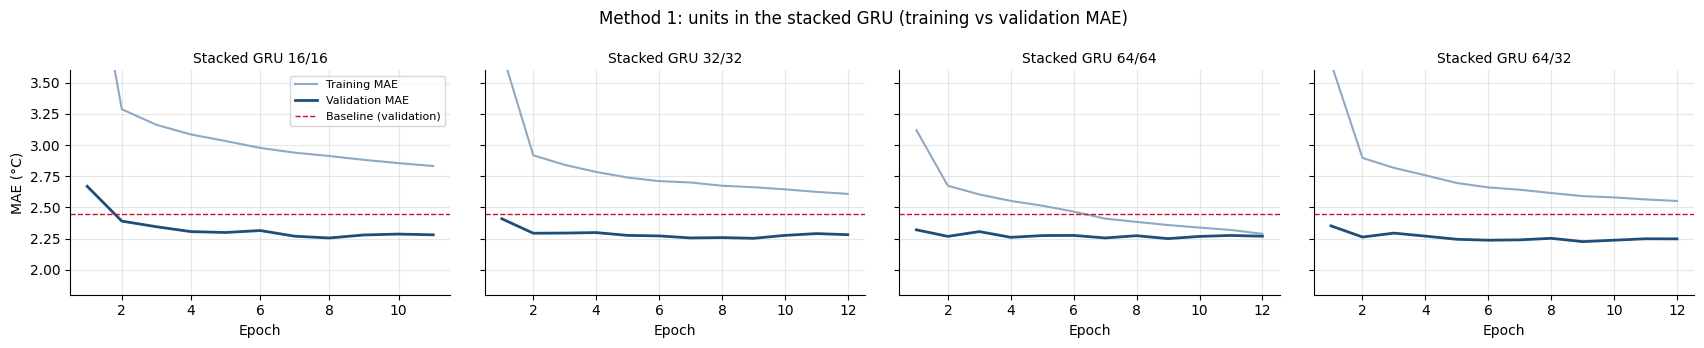

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
method1_ids = ["exp05_gru16x2", "exp06_gru64x2", "exp07_gru64x32"]
train(method1_ids)
display(results_table())
plot_curves(["exp05_gru16x2", "exp04_gru32x2", "exp06_gru64x2", "exp07_gru64x32"],
            "Method 1: units in the stacked GRU (training vs validation MAE)", "fig_curves_method1_units.png")
backup_results()

## 8. Method 2: LSTM instead of GRU
The same stacked setup with LSTM layers in place of GRU layers, at two sizes: 32/32 (the class setup) and the best size from Method 1 (64/64 if 32/32 was best). The size is picked automatically from the Method 1 validation results, so the GRU and LSTM are compared like for like.

Best stacked GRU in Method 1: exp07_gru64x32 (2.226 °C) -> second LSTM uses 64/32 units
Epoch 1/30
818/818 - 335s - 409ms/step - loss: 27.1507 - mae: 3.8555 - val_loss: 9.7562 - val_mae: 2.4236 - learning_rate: 0.0010
Epoch 2/30
818/818 - 31s - 37ms/step - loss: 14.4430 - mae: 2.9524 - val_loss: 9.1811 - val_mae: 2.3500 - learning_rate: 0.0010
Epoch 3/30
818/818 - 30s - 37ms/step - loss: 13.5350 - mae: 2.8505 - val_loss: 9.1413 - val_mae: 2.3448 - learning_rate: 0.0010
Epoch 4/30
818/818 - 30s - 37ms/step - loss: 12.7911 - mae: 2.7658 - val_loss: 9.0681 - val_mae: 2.3360 - learning_rate: 0.0010
Epoch 5/30
818/818 - 30s - 37ms/step - loss: 12.2220 - mae: 2.7020 - val_loss: 9.1885 - val_mae: 2.3481 - learning_rate: 0.0010
Epoch 6/30
818/818 - 30s - 37ms/step - loss: 11.6632 - mae: 2.6392 - val_loss: 9.1507 - val_mae: 2.3427 - learning_rate: 0.0010
Epoch 7/30
818/818 - 30s - 37ms/step - loss: 11.3139 - mae: 2.5989 - val_loss: 8.9651 - val_mae: 2.3234 - learning_rate: 5.0000e-04
Epoch 8/30

,exp_id,name,method,params,best_val_mae,val gain vs baseline (%),test_mae,train_mae_at_best,best_epoch,epochs_run,seconds_per_epoch,minutes
0,exp00_baseline,Common-sense baseline,Baseline,0,2.444,0.000,2.622,NaN,NaN,NaN,NaN,NaN
1,exp01_dense,"Dense (Flatten, Dense 16)",Course reference,26913,2.481,-1.511,NaN,2.331,2.0,5.0,3.9,0.3
2,exp02_lstm16,LSTM(16),Course reference,2001,2.415,1.220,NaN,2.356,7.0,10.0,7.8,1.3
3,exp03_lstm32_rd,LSTM(32) + recurrent dropout,Course reference,6049,2.291,6.277,NaN,2.782,7.0,10.0,28.9,4.8
4,exp04_gru32x2,Stacked GRU 32/32,Course reference,10977,2.253,7.848,NaN,2.662,9.0,12.0,56.4,11.3
5,exp05_gru16x2,Stacked GRU 16/16,Method 1: units,3185,2.255,7.734,NaN,2.913,8.0,11.0,57.9,10.6
6,exp06_gru64x2,Stacked GRU 64/64,Method 1: units,40385,2.250,7.947,NaN,2.359,9.0,12.0,60.5,12.1
7,exp07_gru64x32,Stacked GRU 64/32,Method 1: units,24801,2.226,8.934,NaN,2.591,9.0,12.0,58.8,11.8
8,exp08_lstm32x2,Stacked LSTM 32/32,Method 2: LSTM vs GRU,14369,2.323,4.947,NaN,2.599,7.0,10.0,60.6,10.1
9,exp09_lstm64x32,Stacked LSTM 64/32,Method 2: LSTM vs GRU,32673,2.329,4.699,NaN,2.892,2.0,5.0,92.0,7.7


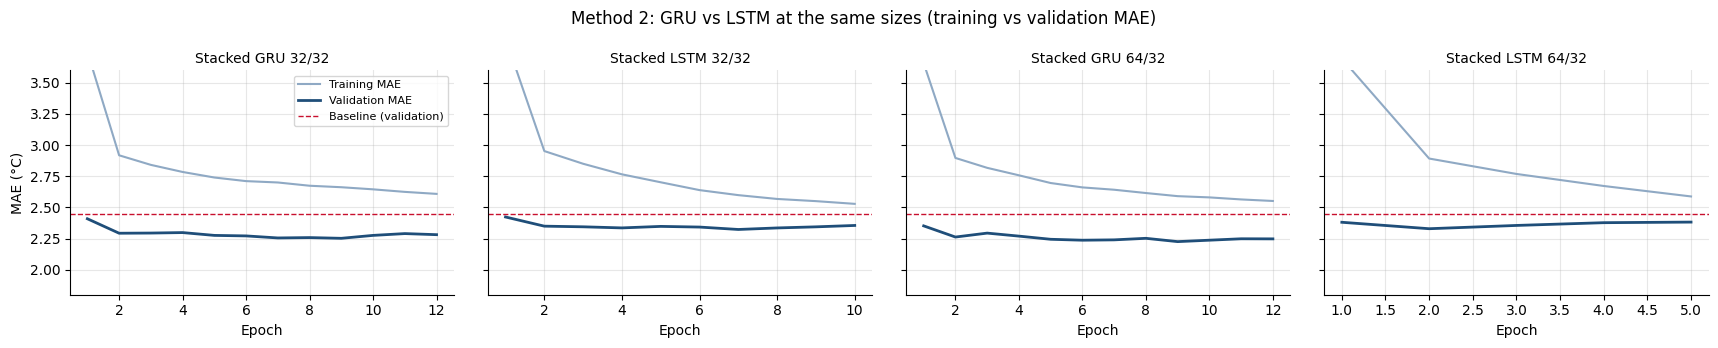

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# The best unit sizes from Method 1 (lowest validation MAE among the stacked GRUs) carry over to the LSTM
unit_runs = {"exp05_gru16x2": (16, 16), "exp04_gru32x2": (32, 32), "exp06_gru64x2": (64, 64), "exp07_gru64x32": (64, 32)}
val_mae = {}
for exp_id in unit_runs:
    with open(f"{RESULTS_DIR}/{exp_id}.json") as f:
        val_mae[exp_id] = json.load(f)["best_val_mae"]
best_gru = min(val_mae, key=val_mae.get)
u1, u2 = unit_runs[best_gru] if unit_runs[best_gru] != (32, 32) else (64, 64)
print(f"Best stacked GRU in Method 1: {best_gru} ({val_mae[best_gru]:.3f} °C) -> second LSTM uses {u1}/{u2} units")

method2_ids = ["exp08_lstm32x2", f"exp09_lstm{u1}x{u2}"]
train(method2_ids)
display(results_table())
gru_match = {v: k for k, v in unit_runs.items()}[(u1, u2)]
plot_curves(["exp04_gru32x2", "exp08_lstm32x2", gru_match, method2_ids[1]],
            "Method 2: GRU vs LSTM at the same sizes (training vs validation MAE)", "fig_curves_method2_lstm.png")
backup_results()

## 9. Method 3: Combining 1D convnets and an RNN
Two Conv1D layers (32 filters, kernel of 6 hours) with max pooling in between pick out short local patterns and halve the sequence from 120 to 60 steps. A recurrent layer (32 units, recurrent dropout 0.5) then reads the shorter sequence in order. In class, a convnet alone failed (about 2.9 °C) because pooling throws away order. Here the RNN restores order sensitivity, and the convolutions make the sequence cheaper to process. Both a GRU and an LSTM version are tested.

Epoch 1/30
818/818 - 85s - 103ms/step - loss: 22.7573 - mae: 3.5411 - val_loss: 11.1369 - val_mae: 2.6008 - learning_rate: 0.0010
Epoch 2/30
818/818 - 10s - 12ms/step - loss: 13.9025 - mae: 2.8835 - val_loss: 8.7361 - val_mae: 2.2968 - learning_rate: 0.0010
Epoch 3/30
818/818 - 10s - 12ms/step - loss: 13.0712 - mae: 2.7953 - val_loss: 9.5553 - val_mae: 2.3931 - learning_rate: 0.0010
Epoch 4/30
818/818 - 10s - 12ms/step - loss: 12.2996 - mae: 2.7116 - val_loss: 9.6364 - val_mae: 2.4106 - learning_rate: 0.0010
Epoch 5/30
818/818 - 10s - 12ms/step - loss: 11.5219 - mae: 2.6172 - val_loss: 9.7370 - val_mae: 2.4277 - learning_rate: 5.0000e-04
exp10_conv_gru | Conv1D + GRU 32: best validation MAE 2.297 °C at epoch 2 of 5 | 15,265 parameters | 2.1 min
Epoch 1/30
818/818 - 82s - 100ms/step - loss: 22.9572 - mae: 3.5537 - val_loss: 9.7741 - val_mae: 2.4144 - learning_rate: 0.0010
Epoch 2/30
818/818 - 11s - 14ms/step - loss: 13.8824 - mae: 2.8790 - val_loss: 8.7058 - val_mae: 2.2918 - learning_r

,exp_id,name,method,params,best_val_mae,val gain vs baseline (%),test_mae,train_mae_at_best,best_epoch,epochs_run,seconds_per_epoch,minutes
0,exp00_baseline,Common-sense baseline,Baseline,0,2.444,0.000,2.622,NaN,NaN,NaN,NaN,NaN
1,exp01_dense,"Dense (Flatten, Dense 16)",Course reference,26913,2.481,-1.511,NaN,2.331,2.0,5.0,3.9,0.3
2,exp02_lstm16,LSTM(16),Course reference,2001,2.415,1.220,NaN,2.356,7.0,10.0,7.8,1.3
3,exp03_lstm32_rd,LSTM(32) + recurrent dropout,Course reference,6049,2.291,6.277,NaN,2.782,7.0,10.0,28.9,4.8
4,exp04_gru32x2,Stacked GRU 32/32,Course reference,10977,2.253,7.848,NaN,2.662,9.0,12.0,56.4,11.3
5,exp05_gru16x2,Stacked GRU 16/16,Method 1: units,3185,2.255,7.734,NaN,2.913,8.0,11.0,57.9,10.6
6,exp06_gru64x2,Stacked GRU 64/64,Method 1: units,40385,2.250,7.947,NaN,2.359,9.0,12.0,60.5,12.1
7,exp07_gru64x32,Stacked GRU 64/32,Method 1: units,24801,2.226,8.934,NaN,2.591,9.0,12.0,58.8,11.8
8,exp08_lstm32x2,Stacked LSTM 32/32,Method 2: LSTM vs GRU,14369,2.323,4.947,NaN,2.599,7.0,10.0,60.6,10.1
9,exp09_lstm64x32,Stacked LSTM 64/32,Method 2: LSTM vs GRU,32673,2.329,4.699,NaN,2.892,2.0,5.0,92.0,7.7


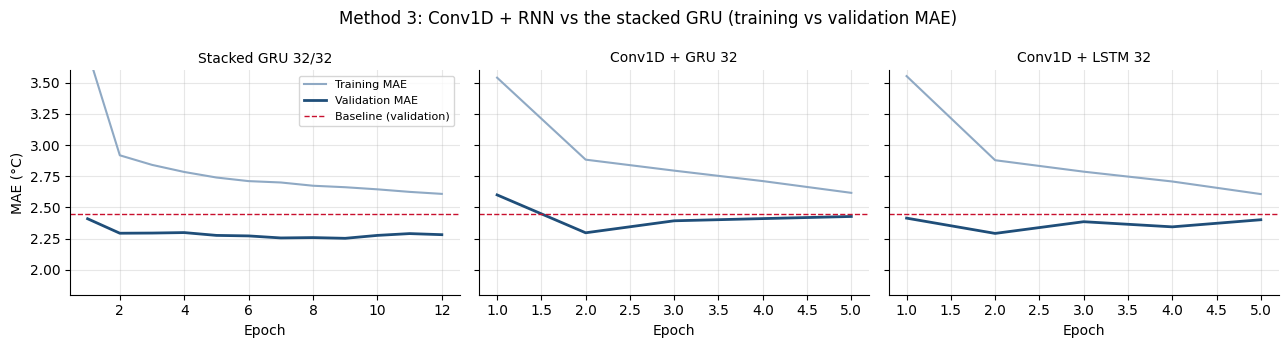

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
method3_ids = ["exp10_conv_gru", "exp11_conv_lstm"]
train(method3_ids)
display(results_table())
plot_curves(["exp04_gru32x2", "exp10_conv_gru", "exp11_conv_lstm"],
            "Method 3: Conv1D + RNN vs the stacked GRU (training vs validation MAE)", "fig_curves_method3_conv.png")
backup_results()

## 10. Test-set evaluation
The rule was fixed before any test result was seen: the three models with the lowest validation MAE are evaluated once on the test set (2015–2016), using the weights from their best validation epoch.

In [10]:
# Rule fixed in advance: the 3 models with the lowest validation MAE are evaluated once on the test set
ranked = results_table().query("exp_id != 'exp00_baseline'").sort_values("best_val_mae")
top_ids = ranked["exp_id"].head(3).tolist()
print("Top 3 by validation MAE:", top_ids)
evaluate_on_test(top_ids)

Top 3 by validation MAE: ['exp07_gru64x32', 'exp06_gru64x2', 'exp04_gru32x2']
exp07_gru64x32 | Stacked GRU 64/32: test MAE 2.413 °C (validation 2.226 °C)
exp06_gru64x2 | Stacked GRU 64/64: test MAE 2.374 °C (validation 2.250 °C)
exp04_gru32x2 | Stacked GRU 32/32: test MAE 2.401 °C (validation 2.253 °C)


## 11. Results
Left: the best validation MAE of every model, coloured by method, with the common-sense baseline as the red line. Right: the three best models on the test set, validation (open circle) against test (filled). The table lists every run; `results_summary.csv` holds the same numbers.

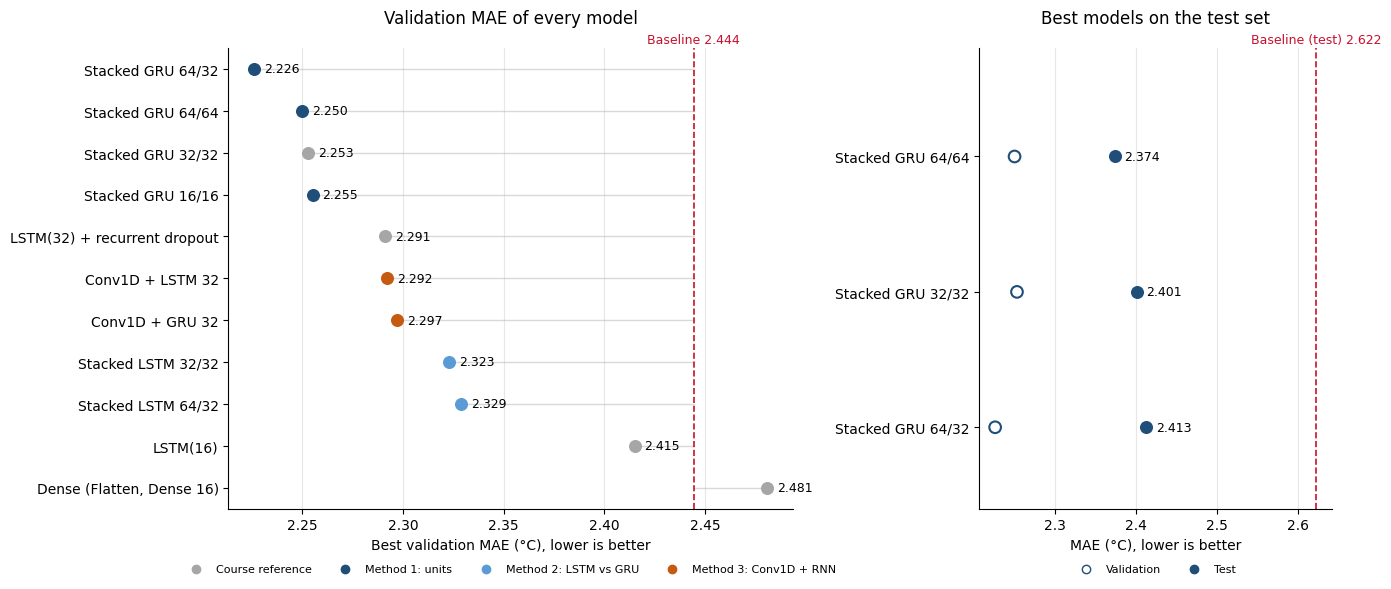

,exp_id,name,method,params,best_val_mae,val gain vs baseline (%),test_mae,test gain vs baseline (%),best_epoch,epochs_run,minutes
0,exp00_baseline,Common-sense baseline,Baseline,0,2.444,0.000,2.622,0.017,NaN,NaN,NaN
1,exp01_dense,"Dense (Flatten, Dense 16)",Course reference,26913,2.481,-1.511,NaN,NaN,2.0,5.0,0.3
2,exp02_lstm16,LSTM(16),Course reference,2001,2.415,1.220,NaN,NaN,7.0,10.0,1.3
3,exp03_lstm32_rd,LSTM(32) + recurrent dropout,Course reference,6049,2.291,6.277,NaN,NaN,7.0,10.0,4.8
4,exp04_gru32x2,Stacked GRU 32/32,Course reference,10977,2.253,7.848,2.401,8.444,9.0,12.0,11.3
5,exp05_gru16x2,Stacked GRU 16/16,Method 1: units,3185,2.255,7.734,NaN,NaN,8.0,11.0,10.6
6,exp06_gru64x2,Stacked GRU 64/64,Method 1: units,40385,2.250,7.947,2.374,9.474,9.0,12.0,12.1
7,exp07_gru64x32,Stacked GRU 64/32,Method 1: units,24801,2.226,8.934,2.413,7.987,9.0,12.0,11.8
8,exp08_lstm32x2,Stacked LSTM 32/32,Method 2: LSTM vs GRU,14369,2.323,4.947,NaN,NaN,7.0,10.0,10.1
9,exp09_lstm64x32,Stacked LSTM 64/32,Method 2: LSTM vs GRU,32673,2.329,4.699,NaN,NaN,2.0,5.0,7.7


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from matplotlib.lines import Line2D
table = results_table()
table["test gain vs baseline (%)"] = (1 - table["test_mae"] / baseline_test_mae) * 100
models = table[table["exp_id"] != "exp00_baseline"].sort_values("best_val_mae", ascending=False).reset_index(drop=True)
colors = {"Course reference": "#A6A6A6", "Method 1: units": "#1F4E79",
          "Method 2: LSTM vs GRU": "#5B9BD5", "Method 3: Conv1D + RNN": "#C55A11"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.6, 1]})
# Left: validation MAE of every model (dot plot, so the axis need not start at zero)
for i, row in models.iterrows():
    ax1.plot([baseline_val_mae, row["best_val_mae"]], [i, i], color="#D9D9D9", linewidth=1, zorder=1)
    ax1.scatter(row["best_val_mae"], i, s=70, color=colors[row["method"]], zorder=2)
    ax1.annotate(f"{row['best_val_mae']:.3f}", (row["best_val_mae"], i), xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
ax1.axvline(baseline_val_mae, color="#C8102E", linestyle="--", linewidth=1.2)
ax1.text(baseline_val_mae, 1.01, f"Baseline {baseline_val_mae:.3f}", color="#C8102E", fontsize=9, ha="center", transform=ax1.get_xaxis_transform())
ax1.set_yticks(range(len(models)), models["name"])
ax1.set_xlabel("Best validation MAE (°C), lower is better")
ax1.set_title("Validation MAE of every model", pad=18)
ax1.legend(handles=[Line2D([], [], marker="o", linestyle="", color=c, label=m) for m, c in colors.items()],
           fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
# Right: the models evaluated on the test set, validation vs test
tested = models.dropna(subset=["test_mae"]).sort_values("test_mae", ascending=False).reset_index(drop=True)
for i, row in tested.iterrows():
    ax2.scatter(row["best_val_mae"], i, s=70, facecolors="none", edgecolors="#1F4E79", linewidths=1.5, zorder=2)
    ax2.scatter(row["test_mae"], i, s=70, color="#1F4E79", zorder=2)
    ax2.annotate(f"{row['test_mae']:.3f}", (max(row["test_mae"], row["best_val_mae"]), i), xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
ax2.axvline(baseline_test_mae, color="#C8102E", linestyle="--", linewidth=1.2)
ax2.text(baseline_test_mae, 1.01, f"Baseline (test) {baseline_test_mae:.3f}", color="#C8102E", fontsize=9, ha="center", transform=ax2.get_xaxis_transform())
ax2.set_yticks(range(len(tested)), tested["name"])
ax2.set_ylim(-0.6, len(tested) - 0.2)
ax2.set_xlabel("MAE (°C), lower is better")
ax2.set_title("Best models on the test set", pad=18)
ax2.legend(handles=[Line2D([], [], marker="o", linestyle="", markerfacecolor="none", color="#1F4E79", label="Validation"),
                    Line2D([], [], marker="o", linestyle="", color="#1F4E79", label="Test")], fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_results_summary.png", dpi=150, bbox_inches="tight")
plt.show()

summary_cols = ["exp_id", "name", "method", "params", "best_val_mae", "val gain vs baseline (%)",
                "test_mae", "test gain vs baseline (%)", "best_epoch", "epochs_run", "minutes"]
summary = table[summary_cols].round(3)
summary.to_csv(f"{RESULTS_DIR}/results_summary.csv", index=False)
display(summary)
backup_results()